# <span style="color:#0b486b">Deep Neural Networks</span>


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
#for ELU
def elu(x, alpha=0.1):
    return np.where(x > 0, x, alpha * (np.exp(x) - 1))

def elu_derivative(x, alpha=0.1):
    return np.where(x > 0, 1, alpha * np.exp(x))

x = np.linspace(-3, 3, 100)
plt.plot(x, elu(x), label="ELU")
plt.plot(x, elu_derivative(x), label="ELU Derivative")
plt.legend()
plt.show()

In [ ]:
from scipy.stats import norm
#for GELU
def gelu(x):
    return x * norm.cdf(x)

def gelu_derivative(x):
    return norm.cdf(x) + x * norm.pdf(x)

plt.plot(x, gelu(x), label="GELU")
plt.plot(x, gelu_derivative(x), label="GELU Derivative")
plt.legend()
plt.show()

In [ ]:
import torch
s = 34557326
torch.manual_seed(s)

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

We first download the `MNIST` dataset and preprocess it.

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),  # Convert the image to a tensor with shape [C, H, W]
    transforms.Normalize((0.5,), (0.5,)),  # Normalize to [-1, 1]
    transforms.Lambda(lambda x: x.view(28*28)) # Flatten the tensor to shape [-1,HW]
])

# Load the MNIST dataset
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

Each data point has dimension `[28,28]`. We need to flatten it to a vector to input to our FFN.

In [ ]:
train_dataset.data = train_data.data.view(-1, 28*28)
test_dataset.data = test_data.data.view(-1, 28*28)

train_data, train_labels = train_dataset.data, train_dataset.targets
test_data, test_labels = test_dataset.data, test_dataset.targets
print(train_data.shape, train_labels.shape)
print(test_data.shape, test_labels.shape)

In [ ]:
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

**Develop the feed-forward neural networks**

need to develop the class `MyLinear` with the following. need to implement the weight matrix and the bias of MyLinear manually.



In [ ]:
class MyLinear(torch.nn.Module):
  def __init__(self, input_size, output_size):
    """
    input_size: the size of the input
    output_size: the size of the output
    """
    super().__init__()
    #Your code here
    self.W = nn.Parameter(torch.randn(output_size, input_size) * 0.01)
    self.b = nn.Parameter(torch.zeros(output_size))

  #forward propagation
  def forward(self, x):
    return torch.matmul(x, self.W.t()) + self.b


need to develop the class `MyFFN` with the following skeleton


In [ ]:
class MyFFN(torch.nn.Module):
  def __init__(self, input_size, num_classes, hidden_sizes, act = nn.ReLU()):
    """
    input_size: the size of the input
    num_classes: the number of classes
    act is the activation function
    hidden_sizes is the list of hidden sizes
    for example input_size = 3, hidden_sizes = [5, 7], num_classes = 4, and act = torch.nn.ReLU()
    means that we are building up a FFN with the confirguration
    (3 (Input) -> 5 (ReLU) -> 7 (ReLU) -> 4 (Output))
    """
    super(MyFFN, self).__init__()
    self.input_size = input_size
    self.num_classes = num_classes
    self.act = act
    self.hidden_sizes = hidden_sizes
    self.num_layers = len(hidden_sizes) + 1
    self.create_FFN()
    self.velocity = [torch.zeros_like(param) for param in self.parameters()]


    self.grad_squared_sum = [torch.zeros_like(param) for param in self.parameters()]

  def create_FFN(self):
    """
    This function creates the feed-forward neural network
    We stack many MyLinear layers
    """
    hidden_sizes = [self.input_size] + self.hidden_sizes + [self.num_classes]
    self.layers = torch.nn.ModuleList()
    #Your code here
    for i in range(len(hidden_sizes) - 1):
        self.layers.append(MyLinear(hidden_sizes[i], hidden_sizes[i + 1]))


  def forward(self,x):
    """
    This implements the forward propagation of the batch x
    This needs to return the prediction probabilities of x
    """

    #Your code here
    for i in range(self.num_layers):
      x = self.layers[i](x)
      if i < (len(self.layers) - 1):
        x = self.act(x)  # Apply activation between layers
    return x

  def compute_loss(self, x, y):
    """
    This function computes the cross-entropy loss
    You can use the built-in CE loss of PyTorch
    """
    #Your code here
    logits = self.forward(x)
    loss = torch.nn.functional.cross_entropy(logits, y)  # Built-in cross-entropy
    return loss

  def update_SGD(self, x, y, learning_rate = 0.01):
    """
    This function updates the model parameters using SGD using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """
    #Your code here
    loss = self.compute_loss(x, y)


    loss.backward()
    with torch.no_grad():
        for layer in self.layers:
          layer.W -= learning_rate * layer.W.grad
          layer.b -= learning_rate * layer.b.grad
          layer.W.grad.zero_()
          layer.b.grad.zero_()
    return loss.item()


  def update_SGDwithMomentum(self, x, y, learning_rate = 0.01, momentum = 0.9):
    """
    This function updates the model parameters using SGD with momentum using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """
    #Your code here
    if not hasattr(self, 'velocity'):
      self.velocity = [(torch.zeros_like(layer.W), torch.zeros_like(layer.b)) for layer in self.layers]

    loss = self.compute_loss(x, y)

    loss.backward()
    with torch.no_grad():
      for i, layer in enumerate(self.layers):
        W_vel, b_vel = self.velocity[i]
        W_vel = momentum * W_vel + learning_rate * layer.W.grad
        b_vel = momentum * b_vel + learning_rate * layer.b.grad

        layer.W -= W_vel
        layer.b -= b_vel

        layer.W.grad.zero_()
        layer.b.grad.zero_()

  def update_AdaGrad(self, x, y, learning_rate = 0.01):
    """
    This function updates the model parameters using AdaGrad using the batch (x,y)
    You need to implement the update rule manually and cannot rely on the built-in optimizer
    """
    #Your code here
    if not hasattr(self, 'grad_sum'):
      self.grad_sum = [(torch.zeros_like(layer.W), torch.zeros_like(layer.b)) for layer in self.layers]

    loss = self.compute_loss(x, y)

    loss.backward()
    with torch.no_grad():
      for i, layer in enumerate(self.layers):
        W_sum, b_sum = self.grad_sum[i]
        W_sum += layer.W.grad ** 2
        b_sum += layer.b.grad ** 2

                    # Update weights and biases using AdaGrad formula
        layer.W -= (learning_rate / (torch.sqrt(W_sum) + epsilon)) * layer.W.grad
        layer.b -= (learning_rate / (torch.sqrt(b_sum) + epsilon)) * layer.b.grad


                    # Zero gradients
        layer.W.grad.zero_()
        layer.b.grad.zero_()

  def __repr__(self):
     layer_reprs = '\n    '.join([repr(layer) for layer in self.layers])
     return f"MyFFN(\n  input_size={self.input_size},\n  num_classes={self.num_classes},\n  hidden_sizes={self.hidden_sizes},\n  layers=[{layer_reprs}])"



In [ ]:
myFFN = MyFFN(input_size = 28*28, num_classes = 10, hidden_sizes = [100, 100], act = torch.nn.ReLU)
myFFN.create_FFN()
print(myFFN)

the code to evaluate the accuracy of the current `myFFN` model on a data loader (e.g., train_loader or test_loader).


In [ ]:
def compute_acc(model, data_loader):
  """
  This function computes the accuracy of the model on a data loader
  """
  #Your code here
  correct = 0
  total = 0
  model.eval()

  with torch.no_grad():
    for x, y in data_loader:
      logits = model(x)
      predictions = torch.argmax(logits, dim=1)
      correct += (predictions == y).sum().item()
      total += y.size(0)
      accuracy = (correct / total) * 100
    return accuracy



the code to evaluate the loss of the current `myFFN` model on a data loader (e.g., train_loader or test_loader).


In [ ]:
def compute_loss(model, data_loader):
  """
  This function computes the loss of the model on a data loader
  """
  #Your code here
  total_loss = 0.0
  total_samples = 0
  model.eval()
  with torch.no_grad():
    for x, y in data_loader:
      loss = model.compute_loss(x, y)
      total_loss += loss.item()
  return total_loss / len(data_loader)


Train on the `MNIST` data with 50 epochs using `updateSGD`.

In [ ]:
num_epochs = 20
for epoch in range(num_epochs):
    for i, (x, y) in enumerate(train_loader):
      myFFN.update_SGD(x, y, learning_rate = 0.01)
    train_acc = compute_acc(myFFN, train_loader)
    train_loss = compute_loss(myFFN, train_loader)
    test_acc = compute_acc(myFFN, test_loader)
    test_loss = compute_loss(myFFN, test_loader)
    print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}%, Test Loss: {test_loss:.4f}, Test Acc: {test_acc*100:.2f}%")

## <span style="color:#0b486b">Deep Neural Networks (DNN) </span>


In the second part, we are going to work with the FashionMNIST dataset for image recognition. It has the exact same format as MNIST (70,000 grayscale images of 28 × 28 pixels each with 10 classes), but the images represent fashion items rather than handwritten digits, so each class is more diverse, and the problem is significantly more challenging than MNIST.

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(1234)

**Load the Fashion MNIST using `torchvision`**

In [ ]:
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

train_dataset_orgin = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

train_dataset_orgin.data = train_dataset_orgin.data.view(-1, 28*28)
test_dataset.data = test_dataset.data.view(-1, 28*28)

print(train_dataset_orgin.data.shape, train_dataset_orgin.targets.shape)
print(test_dataset.data.shape, test_dataset.targets.shape)

N = len(train_dataset_orgin)
print(f"Number of training samples: {N}")
N_train = int(0.9*N)
N_val = N - N_train
print(f"Number of training samples: {N_train}")
print(f"Number of validation samples: {N_val}")

train_dataset, val_dataset = torch.utils.data.random_split(train_dataset_orgin, [N_train, N_val])


train_loader = DataLoader(dataset=train_dataset_orgin, batch_size=64, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=False)

####  <span style="color:red"></span> code to visualize a mini-batch in `train_loader` including its images and labels.



In [ ]:

import matplotlib.pyplot as plt

# Function to visualize images and labels
def visualize_batch(loader):
    images, labels = next(iter(loader))  # Get a mini-batch
    fig, axes = plt.subplots(8, 8, figsize=(12, 12))
    for i in range(64):  # Assuming batch_size = 64
        ax = axes[i // 8, i % 8]
        ax.imshow(images[i].view(28, 28), cmap='gray')
        ax.set_title(f"Label: {labels[i].item()}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

visualize_batch(train_loader)


####<span style="color:red"> the code for the feed-forward neural net using PyTorch



We now develop a feed-forward neural network with the architecture $784 \rightarrow 40(ReLU) \rightarrow 30(ReLU) \rightarrow 10(softmax)$.

In [ ]:

import torch.nn.functional as F
class FashionMNIST_FFN(torch.nn.Module):
    def __init__(self, input_size=784, hidden1=40, hidden2=30, output_size=10):
        super(FashionMNIST_FFN, self).__init__()
        self.fc1 = torch.nn.Linear(input_size, hidden1)
        self.fc2 = torch.nn.Linear(hidden1, hidden2)
        self.fc3 = torch.nn.Linear(hidden2, output_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = F.softmax(self.fc3(x), dim=1)
        return x

model = FashionMNIST_FFN()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


num_epochs = 20

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:

        images = images.view(-1, 28*28)


        optimizer.zero_grad()


        outputs = model(images)
        loss = criterion(outputs, labels)


        loss.backward()
        optimizer.step()


        running_loss += loss.item()

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}')


model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(-1, 28*28)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy of the model on the test set: {accuracy:.2f}%')



####  <span style="color:red"></span> Tuning hyper-parameters with grid search


Assume that you need to tune the number of neurons on the first and second hidden layers $n_1 \in \{20, 40\}$, $n_2 \in \{20, 40\}$  and then use activation function  $act \in \{sigmoid, tanh, relu\}$. The network has the architecture pattern $784 \rightarrow n_1 (act) \rightarrow n_2(act) \rightarrow 10(softmax)$ where $n_1, n_2$, and $act$ are in their grides. the code to tune the hyper-parameters $n_1, n_2$, and $act$.

In [ ]:

import itertools
n1_grid = [20, 40]
n2_grid = [20, 40]
activation_grid = [nn.Sigmoid(), nn.Tanh(), nn.ReLU()]

def train_and_evaluate_model(hidden1, hidden2, activation_fn):
    model = FashionMNIST_FFN(hidden1=hidden1, hidden2=hidden2)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = torch.nn.CrossEntropyLoss()



# Iterate over all combinations
for n1, n2, act_fn in itertools.product(n1_list, n2_list, activation_functions):
    print(f"Training model with n1={n1}, n2={n2}, activation_functions={act_fn}")
    train_and_evaluate_model(n1, n2, act_fn)




####  <span style="color:red">the loss with the form: $loss(p,y)=CE(1_{y},p)+\lambda H(p)$ where $H(p)=-\sum_{i=1}^{M}p_{i}\log p_{i}$ is the entropy of $p$, $p$ is the prediction probabilities of a data point $x$ with the ground-truth label $y$, $1_y$ is an one-hot label, and $\lambda >0$ is a trade-off parameter. Set $\lambda = 0.1$ to train a model.




In [ ]:

def custom_loss(predictions, targets, lambda_value=0.1):
    # Cross entropy loss
    ce_loss = nn.CrossEntropyLoss()(predictions, targets)

    # Entropy regularization
    p = torch.softmax(predictions, dim=1)
    entropy = -torch.sum(p * torch.log(p + 1e-9), dim=1).mean()

    # Total loss
    total_loss = ce_loss + lambda_value * entropy
    return total_loss

model = FashionMNIST_FFN()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
lambda_value = 0.1

# Training loop
num_epochs = 20  # Set number of epochs as required

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images = images.view(-1, 28*28)
        optimizer.zero_grad()
        outputs = model(images)
        loss = custom_loss(outputs, labels, lambda_value)  # Use custom loss function
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}')

# Evaluation
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in test_loader:
        images = images.view(-1, 28*28)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy of the model on the test set: {accuracy:.2f}%')

####  <span style="color:red">Experimenting with **sharpness-aware minimization** technique


Sharpness-aware minimization (SAM) (i.e., [link for main paper](https://openreview.net/pdf?id=6Tm1mposlrM) from Google Deepmind) is a simple yet but efficient technique to improve the generalization ability of deep learning models on unseen data examples.

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy

# SAM Optimizer class
class SAM(torch.optim.Optimizer):
    def __init__(self, params, base_optimizer, rho=0.05, **kwargs):
        self.base_optimizer = base_optimizer(params, **kwargs)
        self.param_groups = self.base_optimizer.param_groups
        self.rho = rho  # Perturbation size

    @torch.no_grad()
    def first_step(self):
        # Save original weights
        for group in self.param_groups:
            for param in group['params']:
                if param.grad is None:
                    continue
                # Compute perturbation
                e_w = param.grad * self.rho / (param.grad.norm() + 1e-12)
                param.add_(e_w)  # Update parameters with perturbation

    @torch.no_grad()
    def second_step(self):
        # Restore original weights
        for group in self.param_groups:
            for param in group['params']:
                if param.grad is None:
                    continue
                # Reset the weight
                e_w = param.grad * self.rho / (param.grad.norm() + 1e-12)
                param.sub_(2 * e_w)  # Reverse the perturbation

    def step(self, closure=None):
        closure = torch.enable_grad()(closure)
        self.first_step()  # First SAM step
        closure()
        self.second_step()  # Second SAM step
        self.base_optimizer.step()  # Final optimizer step

# Apply SAM to best architecture from Question 2.3
def train_with_sam(model, train_loader, val_loader, num_epochs=10, rho=0.05):
    criterion = nn.CrossEntropyLoss()
    base_optimizer = optim.Adam
    optimizer = SAM(model.parameters(), base_optimizer, lr=0.001, rho=rho)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.view(-1, 28*28)  # Flatten images

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # First SAM step
            optimizer.first_step()

            # Zero gradients and compute gradients for perturbed weights
            optimizer.zero_grad()
            loss.backward()

            # Second SAM step and final update
            optimizer.second_step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_acc = 100 * correct / total
        val_acc = evaluate_model(model, val_loader)
        print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {running_loss/len(train_loader):.4f}, Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%")

def evaluate_model(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.view(-1, 28*28)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return 100 * correct / total

# Train the model using SAM on the best architecture from Q2.3
best_n1, best_n2, best_act_fn = 40, 40, nn.ReLU()  # Example from Q2.3, adjust based on actual result
model = FashionMNIST_FFN(hidden_size1=best_n1, hidden_size2=best_n2, activation_fn=best_act_fn)

# Assuming train_loader and val_loader are already defined
train_with_sam(model, train_loader, val_loader, num_epochs=10, rho=0.05)

## <span style="color:#0b486b">Convolutional Neural Networks and Image Classification</span>



**The dataset used for this part is a specific dataset for this unit consisting of approximately $10,000$ images of $20$ classes of Animals, each of which has approximately 500 images. [download here](https://drive.google.com/file/d/1aEkxNWaD02Z8ZNvZzeMefUoY97C-3wTG/view?usp=drive_link)


In [ ]:
import os
import requests
import tarfile
import time
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torchvision.models as models
import torch.nn as nn
import torch
import PIL.Image
import pathlib
from torchsummary import summary
import matplotlib.pyplot as plt
import torch.optim as optim
%matplotlib inline
import numpy as np

# check if CUDA is available
train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(1234)

Download the dataset to the folder of this Google Colab.

In [ ]:
# !gdown --fuzzy https://drive.google.com/file/d/1aEkxNWaD02Z8ZNvZzeMefUoY97C-3wTG/view?usp=drive_link

!gdown --fuzzy https://drive.google.com/file/d/1qdElRqDS4TitXfv_iG_TFQSi9QIfy4uM/view?usp=drive_link # backup url


We unzip the dataset to the folder.

In [ ]:
!unzip -q Animals_Dataset.zip

In [ ]:
data_dir = "./FIT5215_Dataset"

# We resize the images to [3,64,64]
transform = transforms.Compose([transforms.Resize((64,64)),  #resises the image so it can be perfect for our model.
                                      transforms.RandomHorizontalFlip(), # FLips the image w.r.t horizontal axis
                                      #transforms.RandomRotation(4),     #Rotates the image to a specified angel
                                      #transforms.RandomAffine(0, shear=10, scale=(0.8,1.2)), #Performs actions like zooms, change shear angles.
                                      transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # Set the color params
                                      transforms.ToTensor(), # convert the image to tensor so that it can work with torch
                                      transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),  # Normalize the images, each R,G,B value is normalized with mean=0.5 and std=0.5
                                      ])


# Load the dataset using torchvision.datasets.ImageFolder and apply transformations
dataset = datasets.ImageFolder(data_dir, transform=transform)

# Split the dataset into training and validation sets
train_size = int(0.9 * len(dataset))
valid_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, valid_size])

# Example of DataLoader creation for training and validation
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Number of instance in train_set: %s" % len(train_dataset))
print("Number of instance in val_set: %s" % len(val_dataset))

In [ ]:
class_names = ['bird', 'bottle', 'bread', 'butterfly', 'cake', 'cat', 'chicken', 'cow', 'dog', 'duck',
                  'elephant', 'fish', 'handgun', 'horse', 'lion', 'lipstick', 'seal', 'snake', 'spider', 'vase']

In [ ]:
# obtain one batch of training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
images = images.numpy() # convert images to numpy for display

In [ ]:
import math

def imshow(img):
    img = img / 2 + 0.5  # unnormalize
    plt.imshow(np.transpose(img, (1, 2, 0)))  # convert from Tensor image

def visualize_data(images, categories, images_per_row = 8):
    class_names = ['bird', 'bottle', 'bread', 'butterfly', 'cake', 'cat', 'chicken', 'cow', 'dog', 'duck',
                  'elephant', 'fish', 'handgun', 'horse', 'lion', 'lipstick', 'seal', 'snake', 'spider', 'vase']
    n_images = len(images)
    n_rows = math.ceil(float(n_images)/images_per_row)
    fig = plt.figure(figsize=(1.5*images_per_row, 1.5*n_rows))
    fig.patch.set_facecolor('white')
    for i in range(n_images):
        plt.subplot(n_rows, images_per_row, i+1)
        plt.xticks([])
        plt.yticks([])
        imshow(images[i])
        class_index = categories[i]
        plt.xlabel(class_names[class_index])
    plt.show()

In [ ]:
visualize_data(images, labels)

1. `Block confirguration`: Our network consists of many blocks. Each block has the pattern `[conv, batch norm, activation, conv, batch norm, activation, max pool, dropout]`. All convolutional layers have filter size $(3, 3)$, strides $(1, 1)$ and padding = 1, and all max pool layers have strides $(2, 2)$, kernel size $2$, and padding = 0. The network will consists of a few blocks before applying a linear layer to output the logits for the softmax layer.

2. `list_feature_maps`: the number of feature maps in the blocks of the network. For example, if `list_feature_maps = [16, 32, 64]`, our network has two blocks with the input_channels or number of feature maps are `16, 32`, and `64` respectively.
3. `drop_rate`: the keep probability for dropout. Setting `drop_rate` to $0.0$ means not using dropout.
4. `batch_norm`: the batch normalization function is used or not. Setting `batch_norm` to `false` means not using batch normalization.
5. `use_skip`: the skip connection is used in the blocks or not. Setting this to `true` means that we use `1x1` Conv2D with `strides=2` for the skip connection.



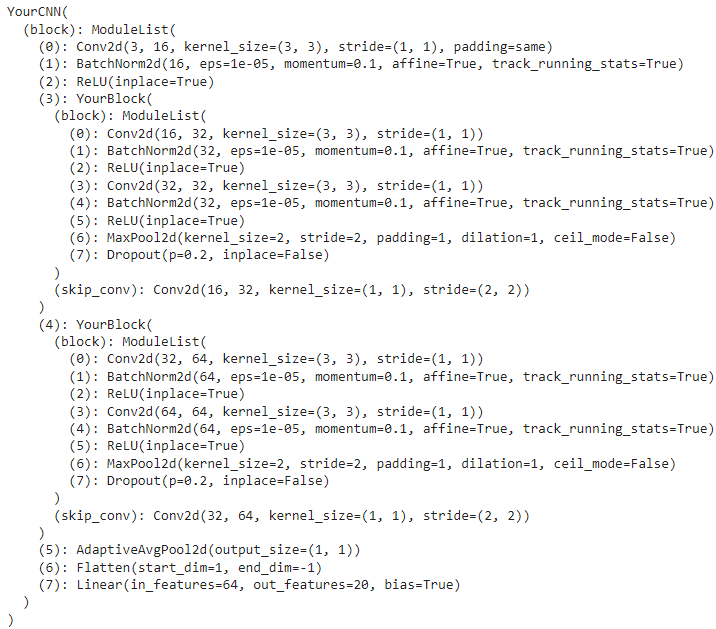

<span style="color:red"></span> **need to implement the aforementioned CNN**.

**First, implement the block of our CNN in the class `YourBlock`.**


In [ ]:

class YourBlock(nn.Module):
  def __init__(self, in_feature_maps, out_feature_maps, drop_rate = 0.2, batch_norm = True, use_skip = True):
    super(YourBlock, self).__init__()
    self.use_skip = use_skip
    #Your code here
    self.conv1 = nn.Conv2d(in_feature_maps, out_feature_maps, kernel_size=3, stride=1, padding=1)
    self.batch_norm1 = nn.BatchNorm2d(out_feature_maps) if batch_norm else nn.Identity()  # Conditionally apply batchnorm
    self.relu1 = nn.ReLU(inplace=True)

        # Second convolutional layer
    self.conv2 = nn.Conv2d(out_feature_maps, out_feature_maps, kernel_size=3, stride=1, padding=1)
    self.batch_norm2 = nn.BatchNorm2d(out_feature_maps) if batch_norm else nn.Identity()
    self.relu2 = nn.ReLU(inplace=True)

        # Max pooling layer
    self.max_pool = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)

        # Dropout layer
    self.dropout = nn.Dropout(p=drop_rate)





  def forward(self, x):
    #Write your code here
    x = self.conv1(x)
    x = self.batch_norm1(x)
    x = self.relu1(x)

        # Second convolution
    x = self.conv2(x)
    x = self.batch_norm2(x)
    x = self.relu2(x)

        # Max pooling and dropout
    x = self.max_pool(x)
    x = self.dropout(x)

    return x






**Second,  to use the above `YourBlock` to implement the class `YourCNN`**.



In [ ]:
class YourCNN(nn.Module):
  def __init__(self, list_feature_maps = [16, 32, 64], drop_rate = 0.2, batch_norm= True, use_skip = True):
    super(YourCNN, self).__init__()
    layers = []
    #Write your code here
    in_feature_maps = 3
    for out_feature_maps in list_feature_maps:
      layers.append(YourBlock(in_feature_maps, out_feature_maps, drop_rate, batch_norm, use_skip))
      in_feature_maps = out_feature_maps
    self.cnn_layers = nn.Sequential(*layers)
    self.fc = nn.Linear(list_feature_maps[-1], 20)
    self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))




  def forward(self, x):
    #Write your code here
    x = self.cnn_layers(x)
    x = self.adaptive_pool(x)

        # Flatten the output before passing it to the fully connected layer
    x = x.view(x.size(0), -1)  # Flatten the tensor
    x = torch.flatten(x, 1)
        # Pass through the fully connected layer
    x = self.fc(x)

    return x



**We declare `my_cnn` from `YourCNN` as follows**.

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
my_cnn = YourCNN(list_feature_maps = [16, 32, 64], use_skip = True)
my_cnn = my_cnn.to(device)
print(my_cnn)

**We declare the optimizer and the loss function.**

In [ ]:
# Loss and optimizer
learning_rate = 0.001
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(my_cnn.parameters(), lr=learning_rate)

**Here are the codes to compute the loss and accuracy.**

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def compute_loss(model, loss_fn, loader):
  loss = 0
  # Set model to eval mode for inference
  model.eval()
  with torch.no_grad():  # No need to track gradients for validation
    for (batchX, batchY) in loader:
      # Move data to the same device as the model
      batchX, batchY = batchX.to(device).type(torch.float32), batchY.to(device).type(torch.long)
      loss += loss_fn(model(batchX), batchY)
  # Set model back to train mode
  model.train()
  return float(loss)/len(loader)

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def compute_acc(model, loader):
    correct = 0
    totals = 0
    # Set model to eval mode for inference
    model.eval()
    for (batchX, batchY) in loader:
        # Move batchX and batchY to the same device as the model
        batchX, batchY = batchX.to(device).type(torch.float32), batchY.to(device)
        outputs = model(batchX)  # feed batch to the model
        totals += batchY.size(0)  # accumulate totals with the current batch size
        predicted = torch.argmax(outputs.data, 1)  # get the predicted class
        # Move batchY to the same device as predicted for comparison
        correct += (predicted == batchY).sum().item()
    return correct / totals

**Here is the code to train our model.**

In [ ]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

def fit(model= None, train_loader = None, valid_loader= None, optimizer = None,
        num_epochs = 10, verbose = True, seed= 1234):
  torch.manual_seed(seed)
  # Move the model to the device before initializing the optimizer
  model.to(device) # Move the model to the GPU

  if optimizer == None:
    optim = torch.optim.Adam(model.parameters(), lr = 0.001) # Now initialize optimizer with model on GPU
  else:
    optim = optimizer
  history = dict()
  history['val_loss'] = list()
  history['val_acc'] = list()
  history['train_loss'] = list()
  history['train_acc'] = list()

  for epoch in range(num_epochs):
    model.train()
    for (X, y) in train_loader:
      # Move input data to the same device as the model
      X,y = X.to(device), y.to(device)
      # Forward pass
      outputs = model(X.type(torch.float32)) # X is already on the correct device
      loss = loss_fn(outputs, y.type(torch.long))
      # Backward and optimize
      optim.zero_grad()
      loss.backward()
      optim.step()
      #losses and accuracies for epoch
    val_loss = compute_loss(model, loss_fn, valid_loader)
    val_acc = compute_acc(model, valid_loader)
    train_loss = compute_loss(model, loss_fn, train_loader)
    train_acc = compute_acc(model, train_loader)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    if not verbose: #verbose = True means we do show the training information during training
      print(f"Epoch {epoch+1}/{num_epochs}")
      print(f"train loss= {train_loss:.4f} - train acc= {train_acc*100:.2f}% - valid loss= {val_loss:.4f} - valid acc= {val_acc*100:.2f}%")
  return history

In [ ]:
history = fit(model= my_cnn, train_loader=train_loader, valid_loader = val_loader, optimizer = optimizer, num_epochs= 10, verbose = False)

<span style="color:red"></span> **Now, let us tune the number of blocks $use\_skip \in \{true,false\}$ and $learning\_rate \in \{0.001, 0.0005\}$.**



In [ ]:
from itertools import product
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Rest of your code
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)


# Define hyperparameters to tune
use_skip_options = [True, False]
learning_rates = [0.001, 0.0005]
list_feature_maps = [32, 64]

# Store best model and its results
best_model = None
best_acc = 0
best_params = {}

# Loop through all combinations of hyperparameters
def evaluate_on_test(model, test_loader):
    model.eval()  # Set the model to evaluation mode
    test_acc = compute_acc(model, test_loader)  # Compute test accuracy
    print(f"Test accuracy: {test_acc*100:.2f}%")
    return test_acc

# Function to save the best model
def save_model(model, path='best_model.pth'):
    torch.save(model.state_dict(), path)
    print(f"Model saved to {path}")

model_dir = './FIT5215_Dataset/models'
os.makedirs(model_dir, exist_ok=True)  # Ensure the directory exists

# Loop through all combinations of hyperparameters using itertools.product
for use_skip, lr in product(use_skip_options, learning_rates):
    print(f"Training with list_feature_maps={list_feature_maps}, use_skip={use_skip}, learning_rate={lr}")

    # Initialize the model with the current hyperparameters
    model = YourCNN(list_feature_maps=list_feature_maps, drop_rate=0.2, batch_norm=True, use_skip=use_skip).to(device)

    # Define optimizer and learning rate scheduler
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, factor=0.5)

    # Train the model (assuming fit function returns training history)
    history = fit(model=model, train_loader=train_loader, valid_loader=val_loader, optimizer=optimizer, num_epochs=10, verbose=True)

    # Get the validation accuracy
    val_acc = compute_acc(model, val_loader)  # Computing validation accuracy at the end of training
    print(f"Validation accuracy: {val_acc*100:.2f}%")

    # Check if this is the best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model
        best_params = {
            "use_skip": use_skip,
            "learning_rate": lr
        }

        # Save the best model
        save_model(best_model, os.path.join(model_dir, 'best_model.pth'))

# Report the best hyperparameters and validation accuracy
print(f"Best model parameters: {best_params}")
print(f"Best validation accuracy: {best_val_acc*100:.2f}%")

# Evaluate the best model on the test set
best_model = YourCNN(list_feature_maps=list_feature_maps, drop_rate=0.2, batch_norm=True, use_skip=best_params['use_skip']).to(device)
best_model.load_state_dict(torch.load(os.path.join(model_dir, 'best_model.pth')))  # Load the best model
test_acc = evaluate_on_test(best_model, test_loader)

**Exploring Data Mixup Technique for Improving Generalization Ability.**
   

Data mixup is another super-simple technique used to boost the generalization ability of deep learning models. We need to incoroporate data mixup technique to the above deep learning model and experiment its performance. There are some papers and documents for data mixup as follows:
- Main paper for data mixup [link for main paper](https://openreview.net/pdf?id=r1Ddp1-Rb) and a good article [article link](https://www.inference.vc/mixup-data-dependent-data-augmentation/).



In [ ]:

def mixup_data(x, y, alpha=0.1):
    """Returns mixed inputs, pairs of targets, and the lambda value"""
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1

    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)

    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

# Loss function with mixup
def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

# Training loop with mixup
def train_with_mixup(model, train_loader, optimizer, alpha=0.1, num_epochs=10):
    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, (inputs, targets) in enumerate(train_loader):
            inputs, targets = inputs.to(device), targets.to(device)

            # Apply mixup
            inputs, targets_a, targets_b, lam = mixup_data(inputs, targets, alpha)
            optimizer.zero_grad()

            # Forward pass
            outputs = model(inputs)
            loss = mixup_criterion(F.cross_entropy, outputs, targets_a, targets_b, lam)

            # Backward pass and optimization
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

# Example usage:
train_with_mixup(best_model, train_loader, optimizer, alpha=0.1, num_epochs=10)

**Exploring CutMix Technique for Improving Generalization Ability.**
   

Data mixup is another super-simple technique used to boost the generalization ability of deep learning models. We need to incoroporate data mixup technique to the above deep learning model and experiment its performance. There are some papers and documents for data mixup as follows:
- Main paper for Cutmix [link for main paper](https://arxiv.org/pdf/1905.04899v2) and a good article [article link](https://shorturl.at/TNwjv).


In [ ]:
class DataAugmentor:
    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def apply_cutmix(self, inputs, targets):
        '''Applies CutMix to the inputs and targets.'''
        batch_size = inputs.size(0)
        lambda_val = np.random.beta(self.alpha, self.alpha)

        shuffled_indices = torch.randperm(batch_size)
        targets_a = targets
        targets_b = targets[shuffled_indices]

        bbx1, bby1, bbx2, bby2 = self._generate_bbox(inputs.size(), lambda_val)
        inputs[:, :, bbx1:bbx2, bby1:bby2] = inputs[shuffled_indices, :, bbx1:bbx2, bby1:bby2]

        # Adjust lambda for the area of the bounding box
        lambda_val = 1 - ((bbx2 - bbx1) * (bby2 - bby1) / (inputs.size()[-1] * inputs.size()[-2]))

        return inputs, targets_a, targets_b, lambda_val

    def _generate_bbox(self, size, lambda_val):
        '''Generates a random bounding box.'''
        W = size[2]
        H = size[3]
        cut_ratio = np.sqrt(1. - lambda_val)
        cut_w = int(W * cut_ratio)
        cut_h = int(H * cut_ratio)

        center_x = np.random.randint(W)
        center_y = np.random.randint(H)

        bbx1 = np.clip(center_x - cut_w // 2, 0, W)
        bby1 = np.clip(center_y - cut_h // 2, 0, H)
        bbx2 = np.clip(center_x + cut_w // 2, 0, W)
        bby2 = np.clip(center_y + cut_h // 2, 0, H)

        return bbx1, bby1, bbx2, bby2

class CutMixLoss(nn.Module):
    def __init__(self, criterion):
        super(CutMixLoss, self).__init__()
        self.criterion = criterion

    def forward(self, predictions, targets_a, targets_b, lambda_val):
        '''Computes the CutMix loss.'''
        return lambda_val * self.criterion(predictions, targets_a) + (1 - lambda_val) * self.criterion(predictions, targets_b)

def train_one_epoch(model, train_loader, optimizer, augmentor, criterion, device):
    '''Trains the model for one epoch.'''
    model.train()
    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        inputs, targets_a, targets_b, lambda_val = augmentor.apply_cutmix(inputs, targets)
        inputs, targets_a, targets_b = inputs.to(device), targets_a.to(device), targets_b.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets_a, targets_b, lambda_val)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total_samples += targets.size(0)
        correct_predictions += (lambda_val * (predicted == targets_a).sum().item() +
                                (1 - lambda_val) * (predicted == targets_b).sum().item())

    avg_loss = total_loss / len(train_loader)
    accuracy = correct_predictions / total_samples

    return avg_loss, accuracy

def evaluate(model, data_loader, criterion, device):
    '''Evaluates the model on the validation or test set.'''
    model.eval()
    total_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            total_loss += criterion.criterion(outputs, targets).item()
            _, predicted = torch.max(outputs, 1)
            total_samples += targets.size(0)
            correct_predictions += (predicted == targets).sum().item()

    avg_loss = total_loss / len(data_loader)
    accuracy = correct_predictions / total_samples

    return avg_loss, accuracy

# Initialize the components
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = YourCNN(list_feature_maps=[32, 64], use_skip=True).to(device)
criterion = CutMixLoss(nn.CrossEntropyLoss())
optimizer = optim.Adam(model.parameters(), lr=0.001)
augmentor = DataAugmentor(alpha=1.0)

# Training and evaluation
num_epochs = 20

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, augmentor, criterion, device)
    val_loss, val_accuracy = evaluate(model, val_loader, criterion, device)

    print(f"Epoch [{epoch + 1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy * 100:.2f}%")

# Final evaluation on the test set
test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Epoch [1/20]
Train Loss: 2.7456, Train Accuracy: 16.39%
Validation Loss: 2.4820, Validation Accuracy: 24.18%
Epoch [2/20]
Train Loss: 2.5740, Train Accuracy: 22.39%
Validation Loss: 2.4111, Validation Accuracy: 24.71%
Epoch [3/20]
Train Loss: 2.4749, Train Accuracy: 24.83%
Validation Loss: 2.0909, Validation Accuracy: 36.22%
Epoch [4/20]
Train Loss: 2.3948, Train Accuracy: 28.10%
Validation Loss: 1.9865, Validation Accuracy: 36.85%


Implement the **one-versus-all (OVA)** loss. The details are as follows:
- You need to apply `the sigmoid activation function` to logits $h = [h_1, h_2,...,h_M]$ instead of `the softmax activation` function as usual to obtain $p = [p_1, p_2,...,p_M]$, meaning that $p_i = sigmoid(h_i), i=1,...,M$. Note that $M$ is the number of classes.
- Given a data example $x$ with the ground-truth label $y$, the idea is to maximize the likelihood $p_y$ and to minimize the likelihoods $p_i, i \neq y$. Therefore, the objective function is to find the model parameters to
  - $\max\left\{ \log p_{y}+\sum_{i\neq y}\log(1-p_{i})\right\}$ or equivalently $\min\left\{ -\log p_{y}-\sum_{i\neq y}\log(1-p_{i})\right\}$.
  - For example, if $M=3$ and $y=2$, you need to minimize $\min\left\{ -\log(1-p_{1})-\log p_{2}-\log(1-p_{3})\right\}$.

Compare the model trained with the OVA loss and the same model trained with the standard cross-entropy loss.


In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim

class OVALoss(nn.Module):
    def __init__(self):
        super(OVALoss, self).__init__()

    def forward(self, logits, labels):
        # Apply sigmoid to logits
        probabilities = torch.sigmoid(logits)

        # Compute the OVA loss
        # Select the probability corresponding to the true class
        true_class_probs = probabilities[torch.arange(logits.size(0)), labels]
        # Compute the negative log likelihood for the true class
        loss_true_class = -torch.log(true_class_probs + 1e-8)  # Add epsilon to avoid log(0)
        # Compute the negative log likelihood for all other classes
        loss_other_classes = -torch.sum(torch.log(1 - probabilities + 1e-8) *
                                         (1 - torch.eye(logits.size(1)).to(logits.device))[torch.arange(logits.size(0)), labels], dim=1)

        # Total loss for the batch
        loss = loss_true_class + loss_other_classes
        return torch.mean(loss)

# Assuming the YourCNN model is already defined
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = YourCNN(list_feature_maps=[32, 64], use_skip=True).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Define the OVA loss and standard cross-entropy loss
ova_loss = OVALoss()
cross_entropy_loss = nn.CrossEntropyLoss()

# Training loop with OVA loss
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss_ova = 0.0
    running_loss_ce = 0.0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        # Forward pass
        outputs = model(inputs)

        # Compute OVA loss
        loss_ova = ova_loss(outputs, labels)
        running_loss_ova += loss_ova.item()

        # Compute Cross-Entropy loss
        loss_ce = cross_entropy_loss(outputs, labels)
        running_loss_ce += loss_ce.item()

        # Backward pass and optimization
        optimizer.zero_grad()
        loss_ova.backward()
        optimizer.step()

    avg_loss_ova = running_loss_ova / len(train_loader)
    avg_loss_ce = running_loss_ce / len(train_loader)

    print(f"Epoch {epoch + 1}/{num_epochs}")
    print(f"OVA Loss: {avg_loss_ova:.4f}")
    print(f"Cross-Entropy Loss: {avg_loss_ce:.4f}")

# Evaluate on test set
def evaluate_model(model, test_loader):
    model.eval()
    test_loss_ova = 0.0
    test_loss_ce = 0.0
    correct_ova = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)

            # Compute OVA loss
            loss_ova = ova_loss(outputs, labels)
            test_loss_ova += loss_ova.item()

            # Compute Cross-Entropy loss
            loss_ce = cross_entropy_loss(outputs, labels)
            test_loss_ce += loss_ce.item()

            # Compute accuracy
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct_ova += (predicted == labels).sum().item()

    avg_test_loss_ova = test_loss_ova / len(test_loader)
    avg_test_loss_ce = test_loss_ce / len(test_loader)
    accuracy = 100 * correct_ova / total

    print(f"Test Loss (OVA): {avg_test_loss_ova:.4f}")
    print(f"Test Loss (Cross-Entropy): {avg_test_loss_ce:.4f}")
    print(f"Test Accuracy: {accuracy:.2f}%")

# Call the evaluation function
evaluate_model(model, test_loader)


**Attack your best obtained model with PGD attacks with $\epsilon= 0.0313, k=20, \eta= 0.002$ on the testing set. Write the code for the attacks and report the robust accuracies. Also choose a random set of 20 clean images in the testing set and visualize the original and attacked images.**


In [ ]:

def pgd_attack(model, images, labels, epsilon=0.0313, alpha=0.002, num_steps=20):
    model.eval()
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    # Initialize perturbations
    perturbed_images = images + torch.zeros_like(images).uniform_(-epsilon, epsilon)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)  # Ensure images are within valid range

    for _ in range(num_steps):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = F.cross_entropy(outputs, labels)
        model.zero_grad()
        loss.backward()
        grad = perturbed_images.grad.data
        perturbed_images = perturbed_images + alpha * torch.sign(grad)
        perturbation = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + perturbation, 0, 1)

    return perturbed_images

# Example usage
def evaluate_pgd_attack(model, test_loader, epsilon=0.0313, alpha=0.002, num_steps=20):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            perturbed_inputs = pgd_attack(model, inputs, labels, epsilon, alpha, num_steps)
            outputs = model(perturbed_inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return correct / total

# Evaluate the model on PGD attacks
robust_accuracy = evaluate_pgd_attack(model, test_loader)
print(f"Robust Accuracy with PGD Attack: {robust_accuracy * 100:.2f}%")


import matplotlib.pyplot as plt
import numpy as np

def visualize_pgd_examples(model, test_loader, num_images=20, epsilon=0.0313, alpha=0.002, num_steps=20):
    model.eval()
    clean_images = []
    attacked_images = []
    labels = []

    with torch.no_grad():
        for inputs, lbls in test_loader:
            if len(clean_images) >= num_images:
                break
            inputs, lbls = inputs.to(device), lbls.to(device)
            perturbed_inputs = pgd_attack(model, inputs, lbls, epsilon, alpha, num_steps)

            for i in range(inputs.size(0)):
                if len(clean_images) >= num_images:
                    break
                clean_images.append(inputs[i].cpu().numpy())
                attacked_images.append(perturbed_inputs[i].cpu().numpy())
                labels.append(lbls[i].item())

    # Plot the images
    fig, axes = plt.subplots(num_images, 2, figsize=(10, num_images * 2))
    for i in range(num_images):
        axes[i, 0].imshow(np.transpose(clean_images[i], (1, 2, 0)))
        axes[i, 0].set_title(f"Original - Label: {labels[i]}")
        axes[i, 0].axis('off')

        axes[i, 1].imshow(np.transpose(attacked_images[i], (1, 2, 0)))
        axes[i, 1].set_title(f"Attacked - Label: {labels[i]}")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Visualize 20 clean and attacked images
visualize_pgd_examples(model, test_loader)



**Train a robust model using adversarial training with PGD ${\epsilon= 0.0313, k=10, \eta= 0.002}$. Write the code for the adversarial training and report the robust accuracies. After finishing the training, we need to store your best robust model in the folder `./models` and load the model to evaluate the robust accuracies for PGD and FGSM attacks with $\epsilon= 0.0313, k=20, \eta= 0.002$ on the testing set.**


In [ ]:

import torch.nn.functional as F

def pgd_attack(model, images, labels, epsilon=0.0313, alpha=0.002, num_steps=10):
    model.eval()
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    perturbed_images = images + torch.zeros_like(images).uniform_(-epsilon, epsilon)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for _ in range(num_steps):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = F.cross_entropy(outputs, labels)
        model.zero_grad()
        loss.backward()
        grad = perturbed_images.grad.data
        perturbed_images = perturbed_images + alpha * torch.sign(grad)
        perturbation = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + perturbation, 0, 1)

    return perturbed_images

def adversarial_training(model, train_loader, epochs=10, epsilon=0.0313, alpha=0.002, num_steps=10, lr=0.001):
    model.train()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Generate adversarial examples
            adv_inputs = pgd_attack(model, inputs, labels, epsilon, alpha, num_steps)

            # Training step
            optimizer.zero_grad()
            outputs = model(adv_inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {running_loss / len(train_loader)}")

    # Save the robust model
    torch.save(model.state_dict(), './models/robust_model.pth')

# Assuming the YourCNN model is already defined and initialized
model = YourCNN(list_feature_maps=[32, 64], use_skip=True).to(device)

# Train the model with adversarial training
adversarial_training(model, train_loader)



def pgd_attack_evaluation(model, images, labels, epsilon=0.0313, alpha=0.002, num_steps=20):
    model.eval()
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    perturbed_images = images + torch.zeros_like(images).uniform_(-epsilon, epsilon)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    for _ in range(num_steps):
        perturbed_images.requires_grad = True
        outputs = model(perturbed_images)
        loss = F.cross_entropy(outputs, labels)
        model.zero_grad()
        loss.backward()
        grad = perturbed_images.grad.data
        perturbed_images = perturbed_images + alpha * torch.sign(grad)
        perturbation = torch.clamp(perturbed_images - images, min=-epsilon, max=epsilon)
        perturbed_images = torch.clamp(images + perturbation, 0, 1)

    return perturbed_images



def fgsm_attack(model, images, labels, epsilon=0.0313):
    model.eval()
    images = images.clone().detach().to(device)
    labels = labels.clone().detach().to(device)

    images.requires_grad = True
    outputs = model(images)
    loss = F.cross_entropy(outputs, labels)
    model.zero_grad()
    loss.backward()
    grad = images.grad.data
    perturbed_images = images + epsilon * torch.sign(grad)
    perturbed_images = torch.clamp(perturbed_images, 0, 1)

    return perturbed_images


def evaluate_robustness(model, test_loader):
    model.load_state_dict(torch.load('./models/robust_model.pth'))
    model.eval()

    # Evaluate robustness under PGD attack
    pgd_accuracy = evaluate_pgd_attack(model, test_loader, epsilon=0.0313, alpha=0.002, num_steps=20)
    print(f"Robust Accuracy with PGD Attack: {pgd_accuracy * 100:.2f}%")

    # Evaluate robustness under FGSM attack
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            perturbed_inputs = fgsm_attack(model, inputs, labels, epsilon=0.0313)
            outputs = model(perturbed_inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    fgsm_accuracy = correct / total
    print(f"Robust Accuracy with FGSM Attack: {fgsm_accuracy * 100:.2f}%")

# Call the evaluation function
evaluate_robustness(model, test_loader)
